In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

print("ALL LIBRARIES IMPORTED SUCCESSFULLY!")

ALL LIBRARIES IMPORTED SUCCESSFULLY!


In [3]:
# %% CELL 2: UPLOAD CLEANED DATASET

import os
import tkinter as tk
from tkinter import filedialog

# Create file selection window
root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)

try:
    file_path = filedialog.askopenfilename(
        parent=root,
        title="Select Your Cleaned Dataset",
        filetypes=[
            ("CSV Files", "*.csv"),
            ("Excel Files", "*.xlsx *.xls"),
            ("All Files", "*.*")
        ]
    )
finally:
    root.destroy()

# Validate selected file
if not file_path:
    raise FileNotFoundError("No dataset selected! Please select your file.")

if not os.path.isfile(file_path):
    raise FileNotFoundError("The selected file does not exist!")

print("======================================")
print("DATASET UPLOADED SUCCESSFULLY!")
print("======================================")
print("File Name:", os.path.basename(file_path))
print("File Location:", file_path)

DATASET UPLOADED SUCCESSFULLY!
File Name: cleaned_dataset (1).xlsx
File Location: C:/Users/Manisha Gajula/OneDrive/Desktop/cleaned_dataset (1).xlsx


In [4]:
df = pd.read_excel(file_path)

print("======================================")
print("CLEANED DATASET LOADED SUCCESSFULLY")
print("======================================")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head(10))

CLEANED DATASET LOADED SUCCESSFULLY
Total Rows: 120
Total Columns: 9


,Year,From State,To State,Coal Type,Trade Type,Quantity (Million Tonnes),Average Price (INR/Tonne),Trade Value (INR Million),Trade Balance Impact (INR Million)
0,2010,andhra pradesh,goa,anthracite coal,inter-state supply,56.15,67.88,3811.46,3811.46
1,2011,arunachal pradesh,madhya pradesh,bituminous coal,inter-state supply,27.00,90.67,2448.09,-2448.09
2,2012,assam,punjab,sub-bituminous coal,inter-state supply,63.92,142.82,9129.05,9129.05
3,2013,bihar,uttarakhand,lignite,inter-state supply,76.37,75.00,5727.75,-5727.75
4,2014,chhattisgarh,goa,anthracite coal,inter-state supply,38.75,68.43,2651.66,2651.66
5,2015,goa,madhya pradesh,bituminous coal,inter-state supply,22.49,123.12,2768.97,-2768.97
6,2016,gujarat,punjab,sub-bituminous coal,inter-state supply,7.12,87.87,625.63,625.63
7,2017,haryana,uttarakhand,lignite,inter-state supply,56.99,127.67,7275.91,-7275.91
8,2018,himachal pradesh,goa,anthracite coal,inter-state supply,22.64,132.77,3005.91,3005.91
9,2019,jharkhand,madhya pradesh,bituminous coal,inter-state supply,69.75,65.75,4586.06,-4586.06


In [5]:
print("DATASET INFORMATION")

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

DATASET INFORMATION

Column Names:
['Year', 'From State', 'To State', 'Coal Type', 'Trade Type', 'Quantity (Million Tonnes)', 'Average Price (INR/Tonne)', 'Trade Value (INR Million)', 'Trade Balance Impact (INR Million)']

Data Types:
Year                                    int64
From State                             object
To State                               object
Coal Type                              object
Trade Type                             object
Quantity (Million Tonnes)             float64
Average Price (INR/Tonne)             float64
Trade Value (INR Million)             float64
Trade Balance Impact (INR Million)    float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 9 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Year                                120 non-null    int64  
 1   From State 

In [6]:
print("MISSING VALUES REPORT")

missing_values = df.isnull().sum()

display(missing_values.to_frame(name="Missing Values"))

print("\nTotal Missing Values:", df.isnull().sum().sum())

MISSING VALUES REPORT


,Missing Values
Year,0
From State,0
To State,0
Coal Type,0
Trade Type,0
Quantity (Million Tonnes),0
Average Price (INR/Tonne),0
Trade Value (INR Million),0
Trade Balance Impact (INR Million),0



Total Missing Values: 0


In [7]:
numeric_columns = [
    "Year",
    "Quantity (Million Tonnes)",
    "Average Price (INR/Tonne)",
    "Trade Value (INR Million)",
    "Trade Balance Impact (INR Million)"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Numerical columns prepared successfully!")

display(df[numeric_columns].describe())

Numerical columns prepared successfully!


,Year,Quantity (Million Tonnes),Average Price (INR/Tonne),Trade Value (INR Million),Trade Balance Impact (INR Million)
count,120.000000,120.000000,120.000000,120.000000,120.000000
mean,2017.933333,44.804583,120.940917,5490.776083,107.946917
std,4.953113,24.564728,32.716313,3552.550213,6558.264581
min,2010.000000,5.050000,65.750000,516.510000,-14642.960000
25%,2014.000000,23.320000,91.537500,2600.767500,-4546.092500
50%,2018.000000,42.105000,124.060000,4569.480000,-214.450000
75%,2022.000000,69.495000,145.872500,7560.112500,4590.952500
max,2026.000000,84.940000,179.470000,14642.960000,14154.660000


In [8]:
output_folder = os.path.join(
    os.path.dirname(file_path),
    "Coal_Trade_Visualizations"
)

os.makedirs(output_folder, exist_ok=True)

print("Visualization folder created successfully!")
print("Folder location:", output_folder)

Visualization folder created successfully!
Folder location: C:/Users/Manisha Gajula/OneDrive/Desktop\Coal_Trade_Visualizations


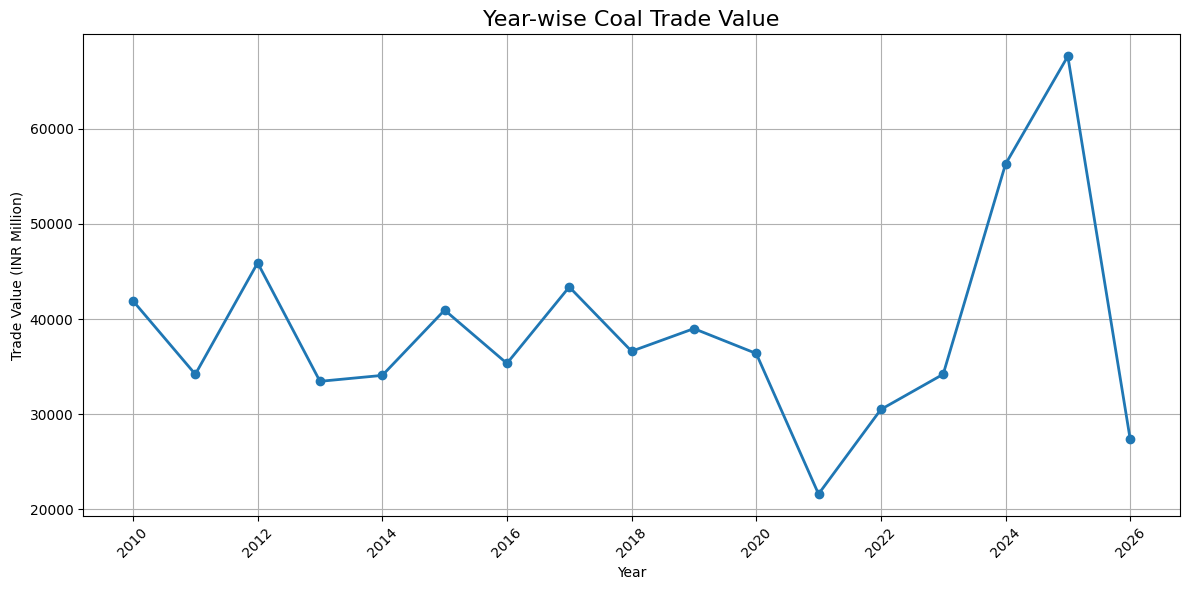

In [9]:
year_analysis = df.groupby("Year")[
    "Trade Value (INR Million)"
].sum()

plt.figure(figsize=(12, 6))

plt.plot(
    year_analysis.index,
    year_analysis.values,
    marker="o",
    linewidth=2
)

plt.title("Year-wise Coal Trade Value", fontsize=16)
plt.xlabel("Year")
plt.ylabel("Trade Value (INR Million)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "01_yearly_trade_value.png"),
    dpi=300
)

plt.show()

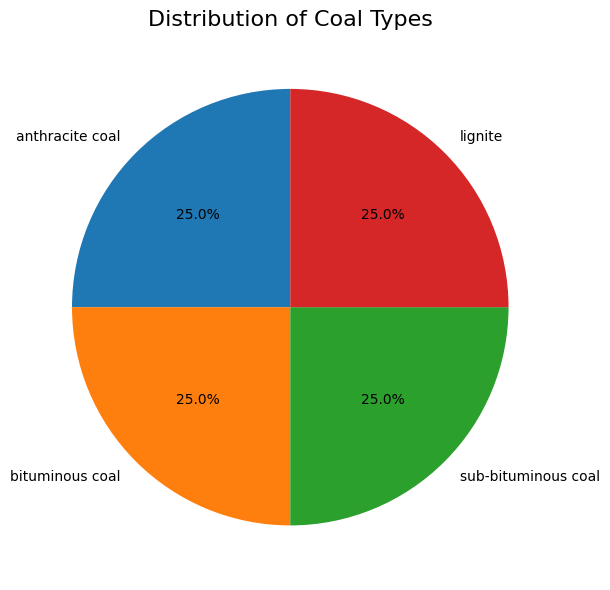

In [10]:
coal_analysis = df["Coal Type"].value_counts()

plt.figure(figsize=(9, 6))

plt.pie(
    coal_analysis,
    labels=coal_analysis.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Coal Types", fontsize=16)
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "02_coal_type_distribution.png"),
    dpi=300
)

plt.show()

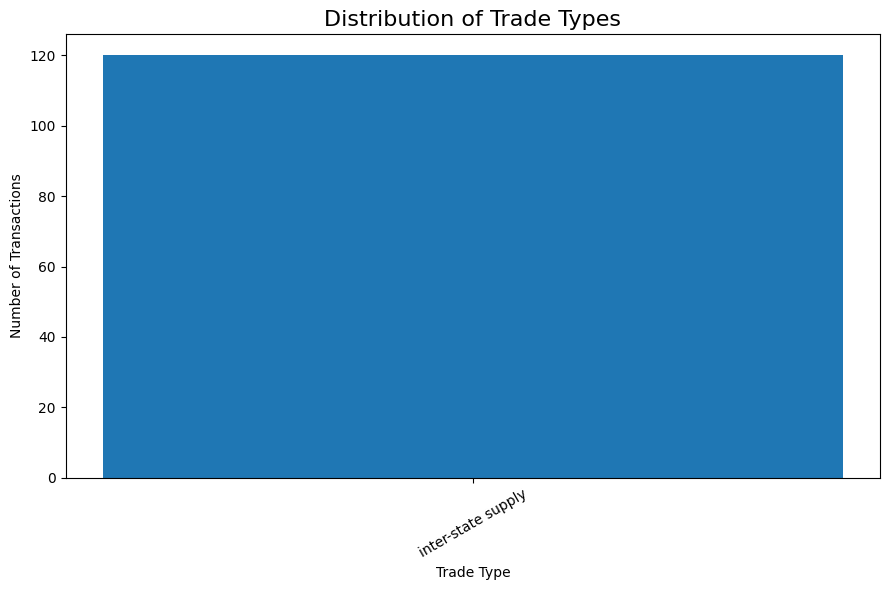

In [11]:
trade_analysis = df["Trade Type"].value_counts()

plt.figure(figsize=(9, 6))

plt.bar(
    trade_analysis.index.astype(str),
    trade_analysis.values
)

plt.title("Distribution of Trade Types", fontsize=16)
plt.xlabel("Trade Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "03_trade_type_distribution.png"),
    dpi=300
)

plt.show()

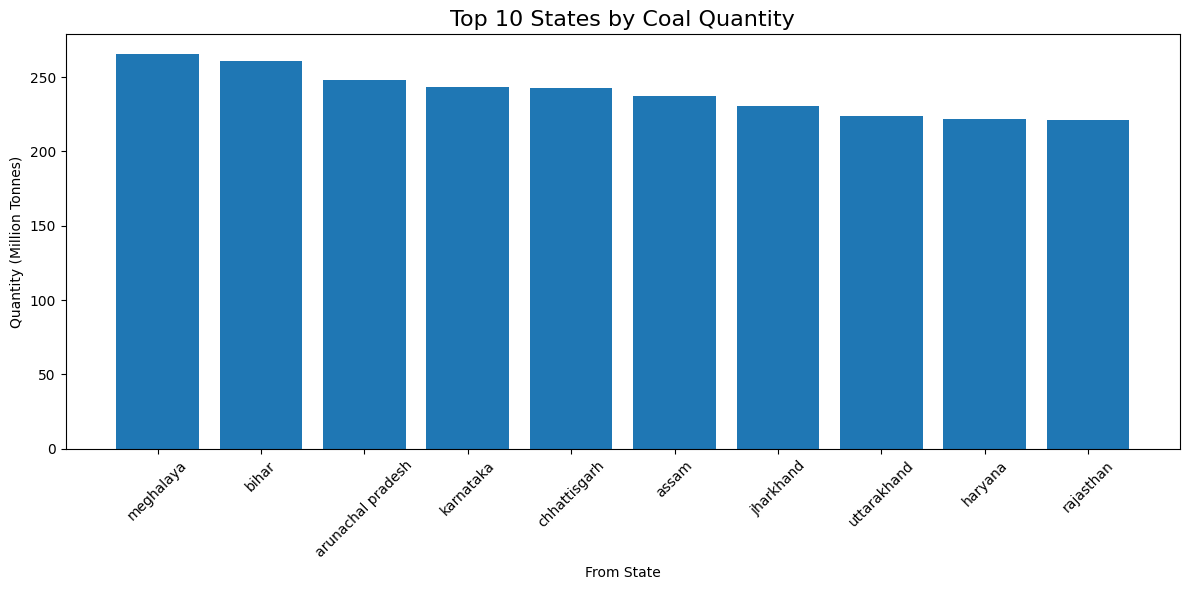

In [12]:
state_analysis = df.groupby("From State")[
    "Quantity (Million Tonnes)"
].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    state_analysis.index.astype(str),
    state_analysis.values
)

plt.title("Top 10 States by Coal Quantity", fontsize=16)
plt.xlabel("From State")
plt.ylabel("Quantity (Million Tonnes)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "04_state_wise_quantity.png"),
    dpi=300
)

plt.show()

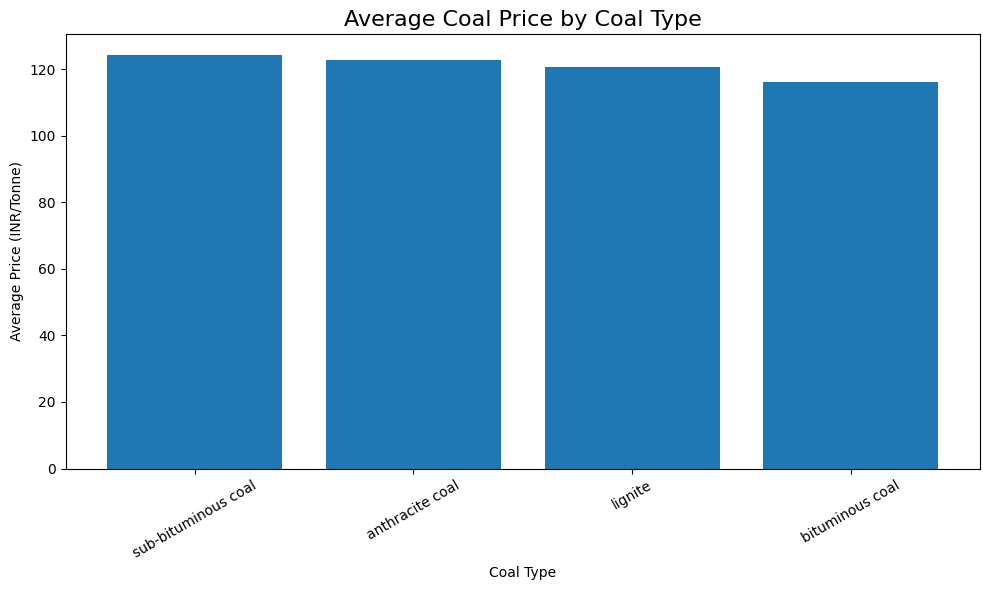

In [13]:
price_analysis = df.groupby("Coal Type")[
    "Average Price (INR/Tonne)"
].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

plt.bar(
    price_analysis.index.astype(str),
    price_analysis.values
)

plt.title("Average Coal Price by Coal Type", fontsize=16)
plt.xlabel("Coal Type")
plt.ylabel("Average Price (INR/Tonne)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "05_average_price_by_coal_type.png"),
    dpi=300
)

plt.show()

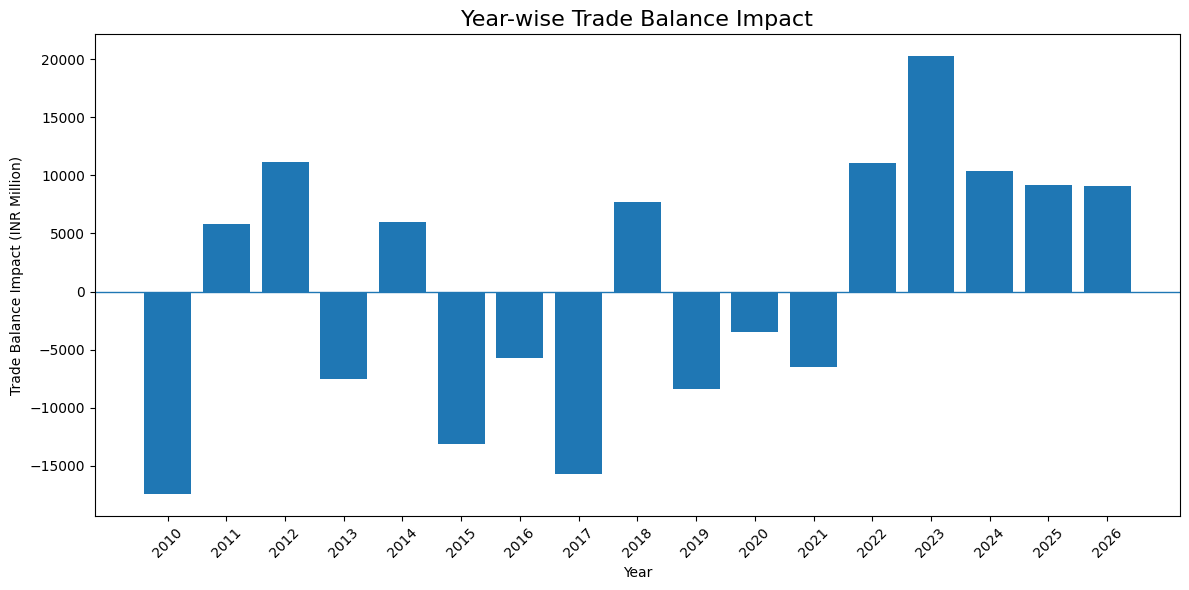

In [14]:
balance_analysis = df.groupby("Year")[
    "Trade Balance Impact (INR Million)"
].sum()

plt.figure(figsize=(12, 6))

plt.bar(
    balance_analysis.index.astype(str),
    balance_analysis.values
)

plt.title("Year-wise Trade Balance Impact", fontsize=16)
plt.xlabel("Year")
plt.ylabel("Trade Balance Impact (INR Million)")
plt.xticks(rotation=45)
plt.axhline(y=0, linewidth=1)
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "06_trade_balance_impact.png"),
    dpi=300
)

plt.show()

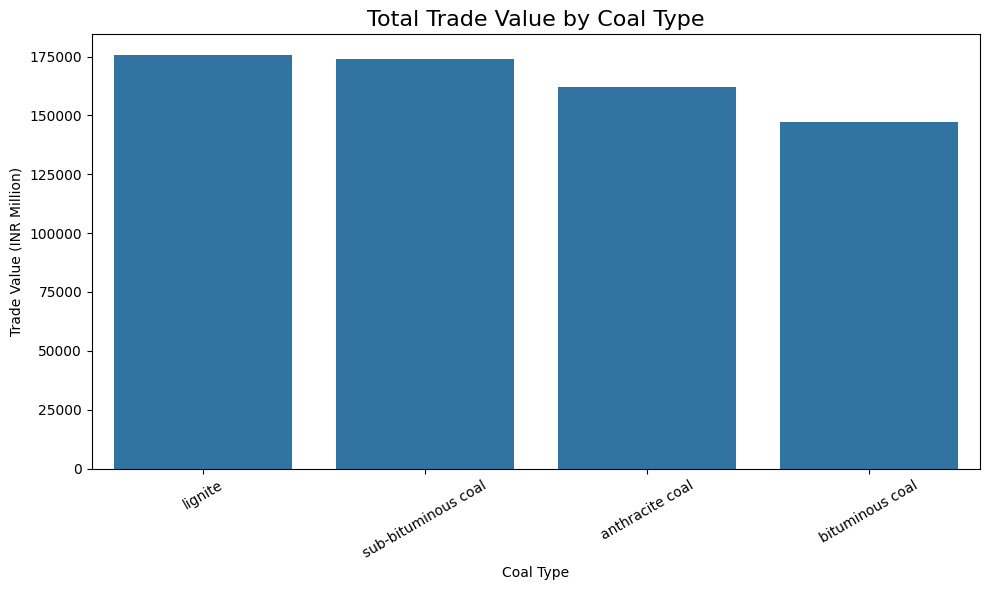

In [16]:
trade_value_analysis = df.groupby("Coal Type")[
    "Trade Value (INR Million)"
].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=trade_value_analysis.index,
    y=trade_value_analysis.values
)

plt.title("Total Trade Value by Coal Type", fontsize=16)
plt.xlabel("Coal Type")
plt.ylabel("Trade Value (INR Million)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "08_trade_value_by_coal_type.png"),
    dpi=300
)

plt.show()

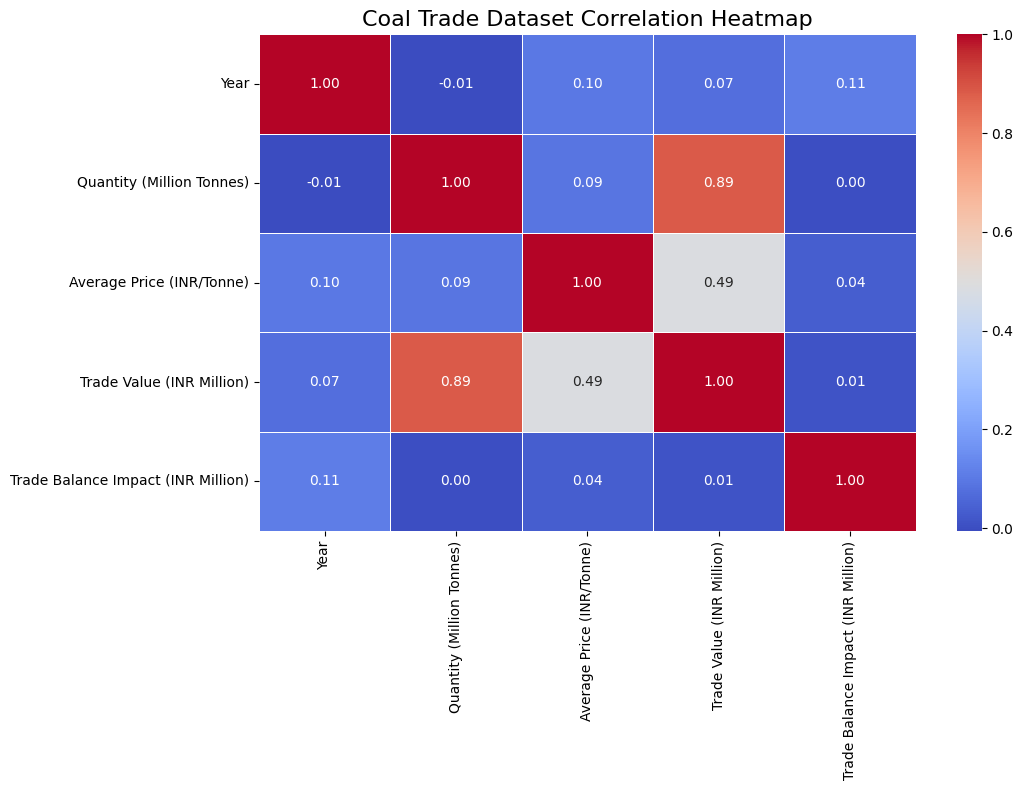

In [17]:
correlation_data = df[numeric_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Coal Trade Dataset Correlation Heatmap", fontsize=16)
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "09_correlation_heatmap.png"),
    dpi=300
)

plt.show()

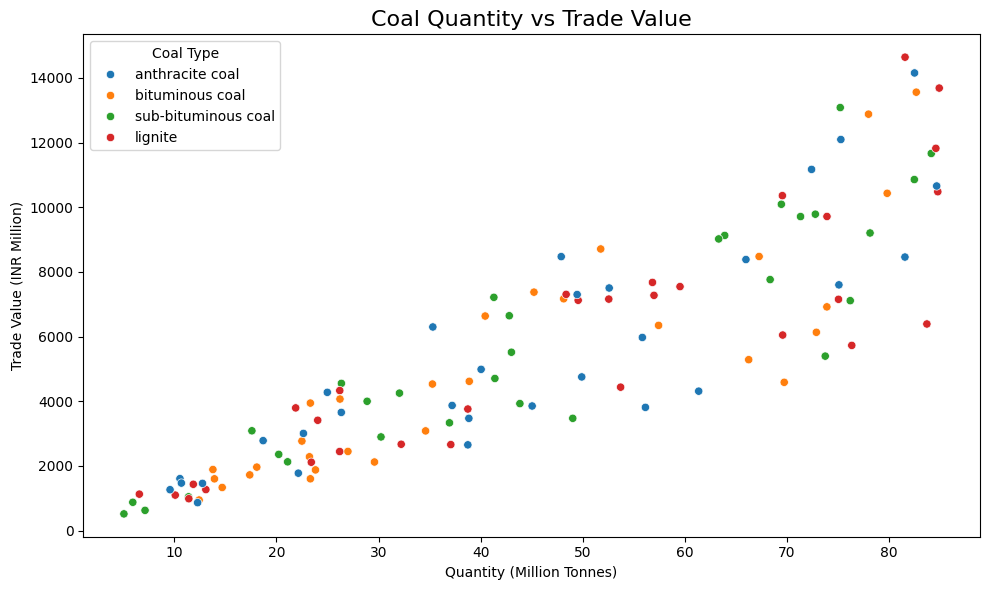

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Quantity (Million Tonnes)",
    y="Trade Value (INR Million)",
    hue="Coal Type"
)

plt.title("Coal Quantity vs Trade Value", fontsize=16)
plt.xlabel("Quantity (Million Tonnes)")
plt.ylabel("Trade Value (INR Million)")
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "10_quantity_vs_trade_value.png"),
    dpi=300
)

plt.show()

In [19]:
visualization_summary = pd.DataFrame({
    "Visualization": [
        "Year-wise Trade Value",
        "Coal Type Distribution",
        "Trade Type Distribution",
        "State-wise Coal Quantity",
        "Average Price by Coal Type",
        "Trade Balance Impact",
        "Quantity Distribution",
        "Trade Value by Coal Type",
        "Correlation Heatmap",
        "Quantity vs Trade Value"
    ],
    "Status": ["Completed"] * 10
})

display(visualization_summary)

visualization_summary.to_excel(
    os.path.join(output_folder, "Visualization_Summary.xlsx"),
    index=False
)

print("Visualization summary saved successfully!")

,Visualization,Status
0,Year-wise Trade Value,Completed
1,Coal Type Distribution,Completed
2,Trade Type Distribution,Completed
3,State-wise Coal Quantity,Completed
4,Average Price by Coal Type,Completed
5,Trade Balance Impact,Completed
6,Quantity Distribution,Completed
7,Trade Value by Coal Type,Completed
8,Correlation Heatmap,Completed
9,Quantity vs Trade Value,Completed


Visualization summary saved successfully!


In [20]:
import glob

image_files = glob.glob(
    os.path.join(output_folder, "*.png")
)

print("============================================")
print("  COAL TRADE DATA VISUALIZATION COMPLETED")
print("============================================")

print("Total Visualizations Created:", len(image_files))

print("\nGenerated Visualization Files:")

for image in sorted(image_files):
    print(os.path.basename(image))

print("\nOutput Folder:")
print(output_folder)

print("\nSUCCESS! ALL VISUALIZATIONS GENERATED.")

  COAL TRADE DATA VISUALIZATION COMPLETED
Total Visualizations Created: 9

Generated Visualization Files:
01_yearly_trade_value.png
02_coal_type_distribution.png
03_trade_type_distribution.png
04_state_wise_quantity.png
05_average_price_by_coal_type.png
06_trade_balance_impact.png
08_trade_value_by_coal_type.png
09_correlation_heatmap.png
10_quantity_vs_trade_value.png

Output Folder:
C:/Users/Manisha Gajula/OneDrive/Desktop\Coal_Trade_Visualizations

SUCCESS! ALL VISUALIZATIONS GENERATED.


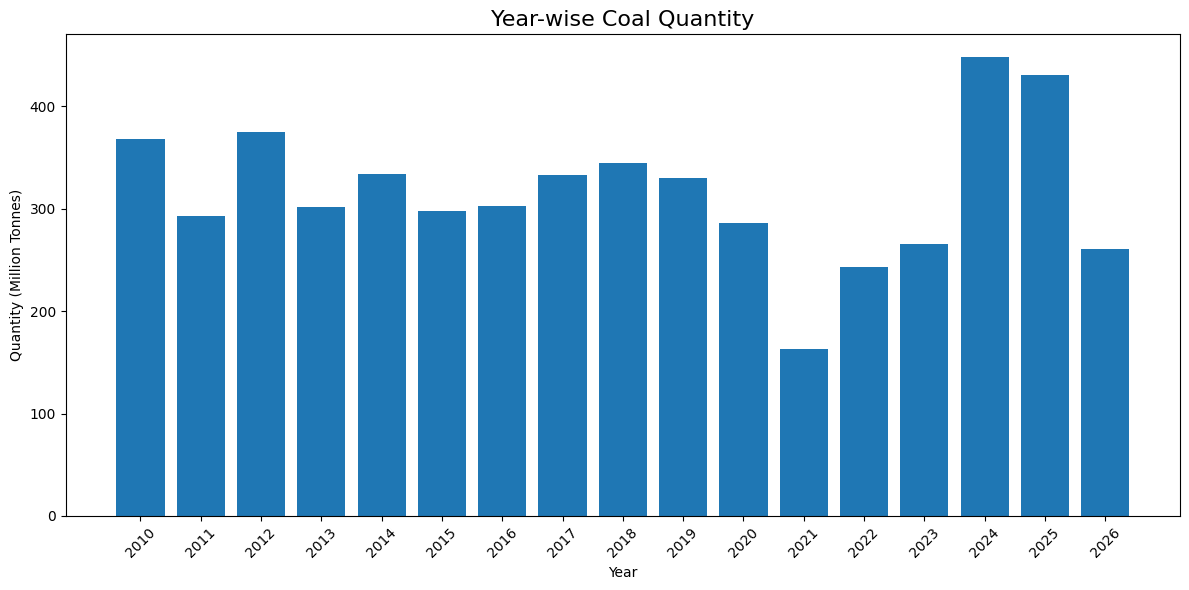

In [21]:
year_quantity = df.groupby("Year")[
    "Quantity (Million Tonnes)"
].sum()

plt.figure(figsize=(12, 6))

plt.bar(year_quantity.index.astype(str), year_quantity.values)

plt.title("Year-wise Coal Quantity", fontsize=16)
plt.xlabel("Year")
plt.ylabel("Quantity (Million Tonnes)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "11_year_wise_coal_quantity.png"), dpi=300)
plt.show()

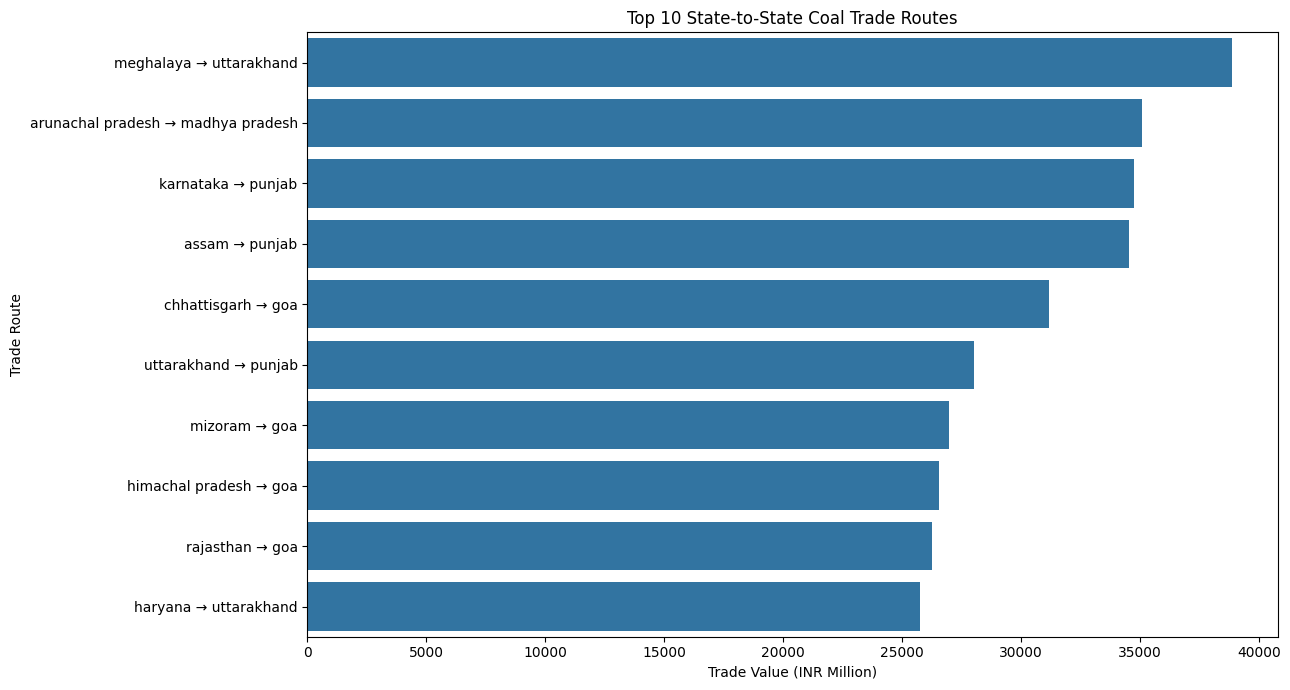

In [22]:
state_trade = df.groupby(
    ["From State", "To State"]
)["Trade Value (INR Million)"].sum().reset_index()

state_trade["Route"] = (
    state_trade["From State"].astype(str)
    + " → "
    + state_trade["To State"].astype(str)
)

top_routes = state_trade.nlargest(10, "Trade Value (INR Million)")

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_routes,
    x="Trade Value (INR Million)",
    y="Route"
)

plt.title("Top 10 State-to-State Coal Trade Routes")
plt.xlabel("Trade Value (INR Million)")
plt.ylabel("Trade Route")

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "12_state_to_state_trade.png"), dpi=300)
plt.show()

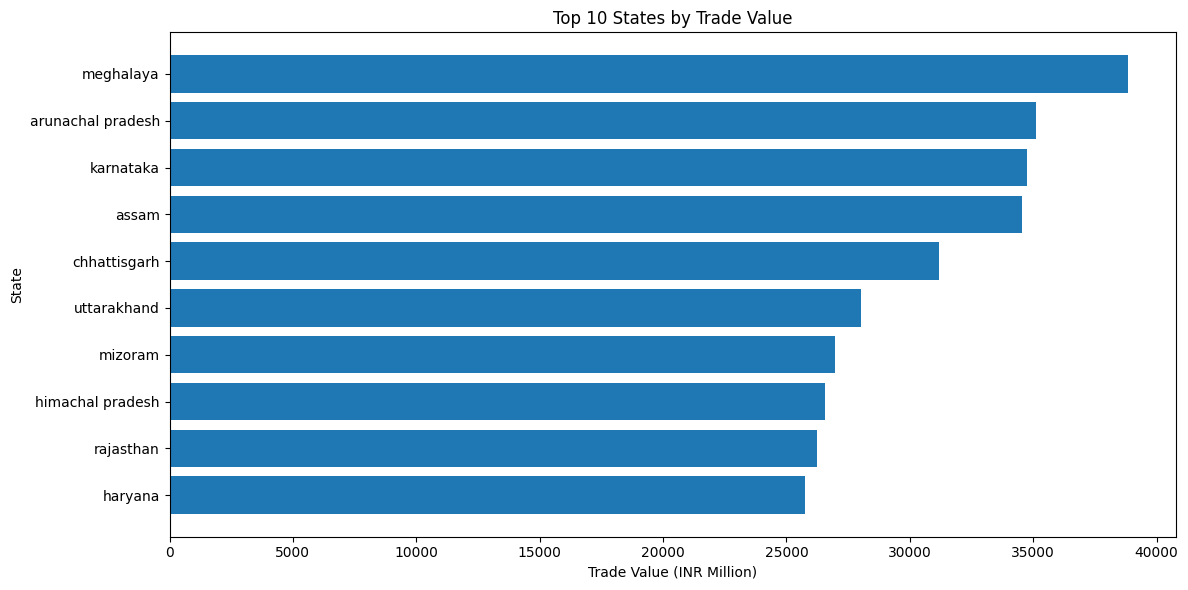

In [23]:
top_states = df.groupby("From State")[
    "Trade Value (INR Million)"
].sum().nlargest(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_states.index.astype(str),
    top_states.values
)

plt.title("Top 10 States by Trade Value")
plt.xlabel("Trade Value (INR Million)")
plt.ylabel("State")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(os.path.join(output_folder, "13_top_trading_states.png"), dpi=300)
plt.show()

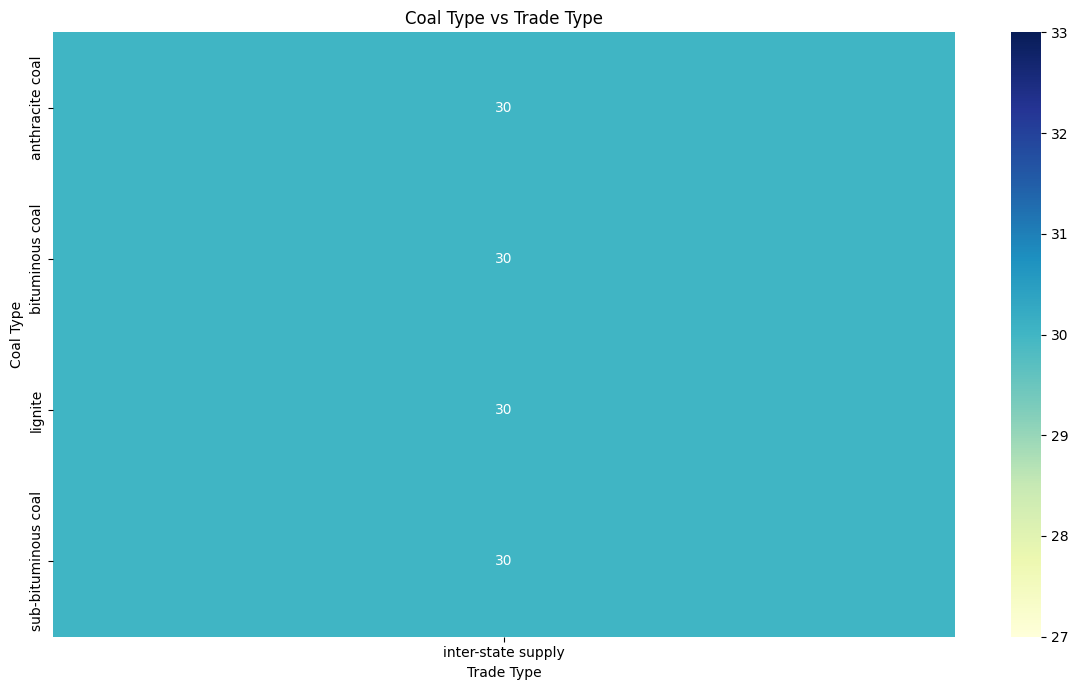

In [24]:
coal_trade_comparison = pd.crosstab(
    df["Coal Type"],
    df["Trade Type"]
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    coal_trade_comparison,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Coal Type vs Trade Type")
plt.xlabel("Trade Type")
plt.ylabel("Coal Type")

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "14_coal_vs_trade_type.png"), dpi=300)
plt.show()

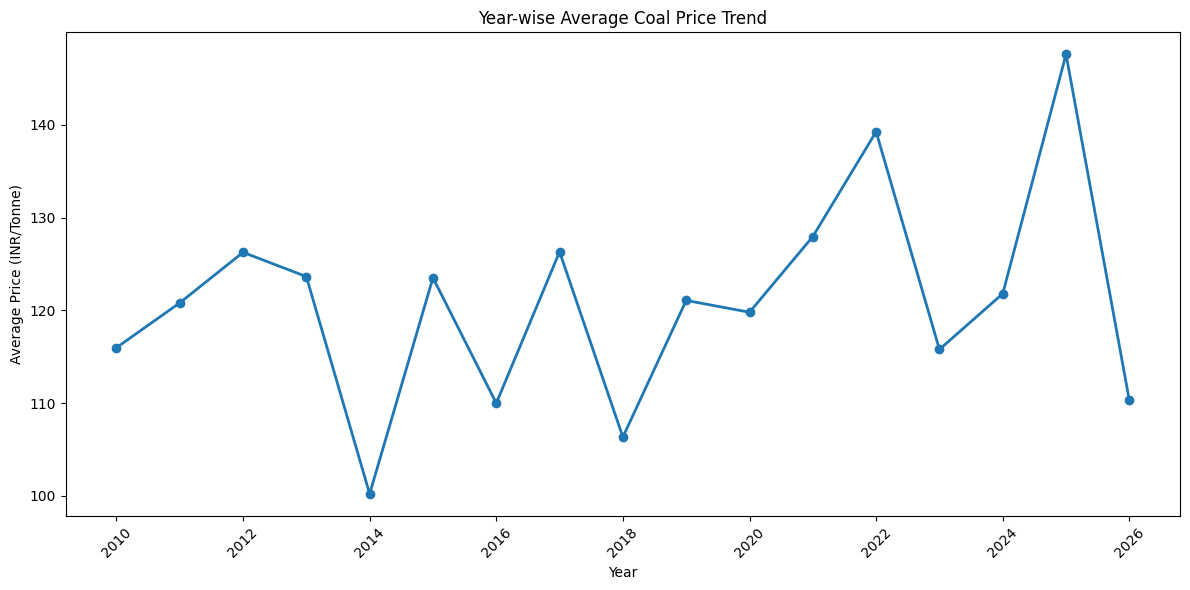

In [25]:
price_trend = df.groupby("Year")[
    "Average Price (INR/Tonne)"
].mean()

plt.figure(figsize=(12, 6))

plt.plot(
    price_trend.index,
    price_trend.values,
    marker="o",
    linewidth=2
)

plt.title("Year-wise Average Coal Price Trend")
plt.xlabel("Year")
plt.ylabel("Average Price (INR/Tonne)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "15_average_price_trend.png"), dpi=300)
plt.show()

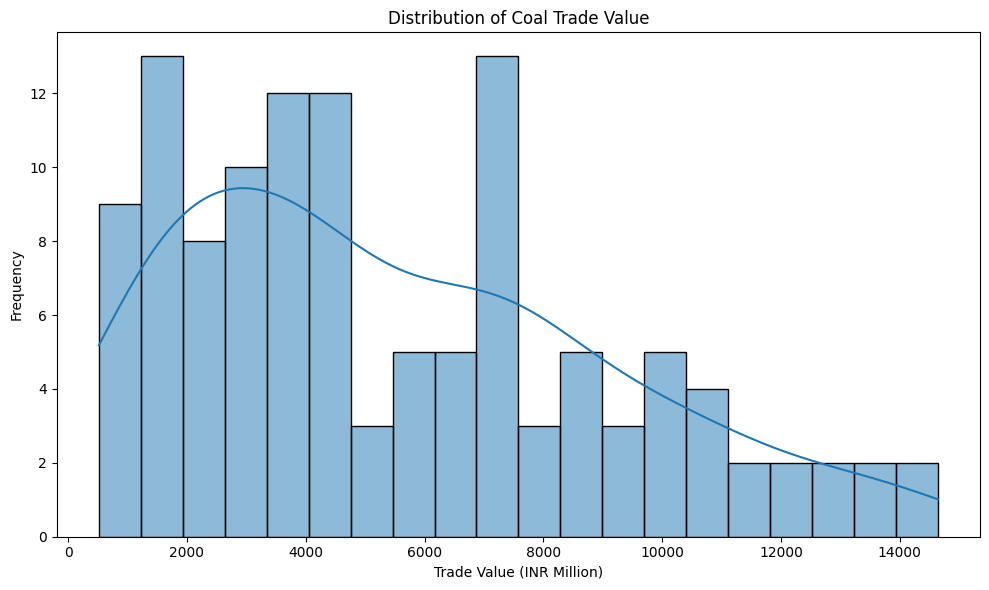

In [26]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Trade Value (INR Million)",
    bins=20,
    kde=True
)

plt.title("Distribution of Coal Trade Value")
plt.xlabel("Trade Value (INR Million)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "16_trade_value_distribution.png"), dpi=300)
plt.show()

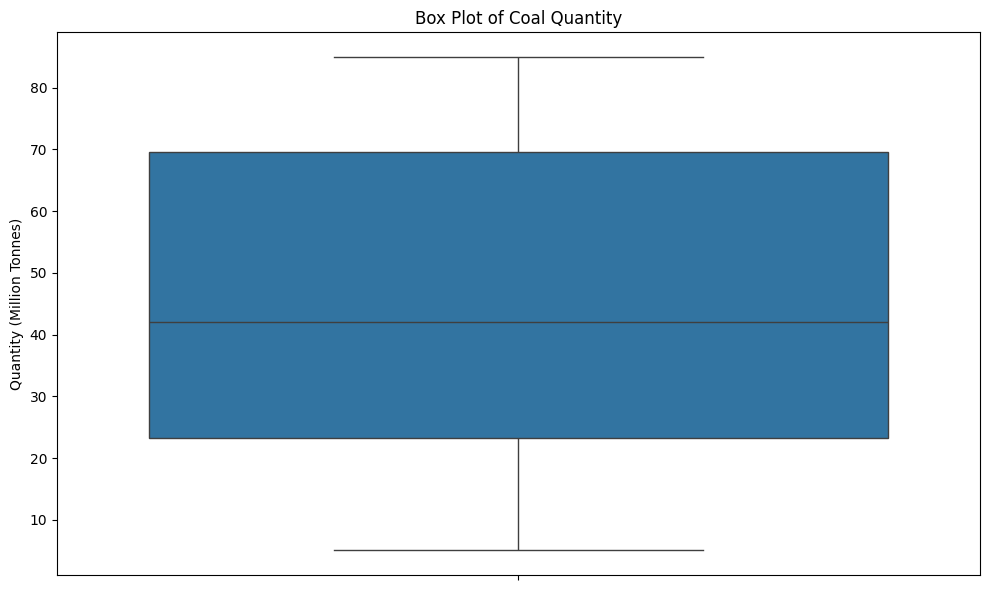

In [27]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    y=df["Quantity (Million Tonnes)"]
)

plt.title("Box Plot of Coal Quantity")
plt.ylabel("Quantity (Million Tonnes)")

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "17_quantity_boxplot.png"), dpi=300)
plt.show()

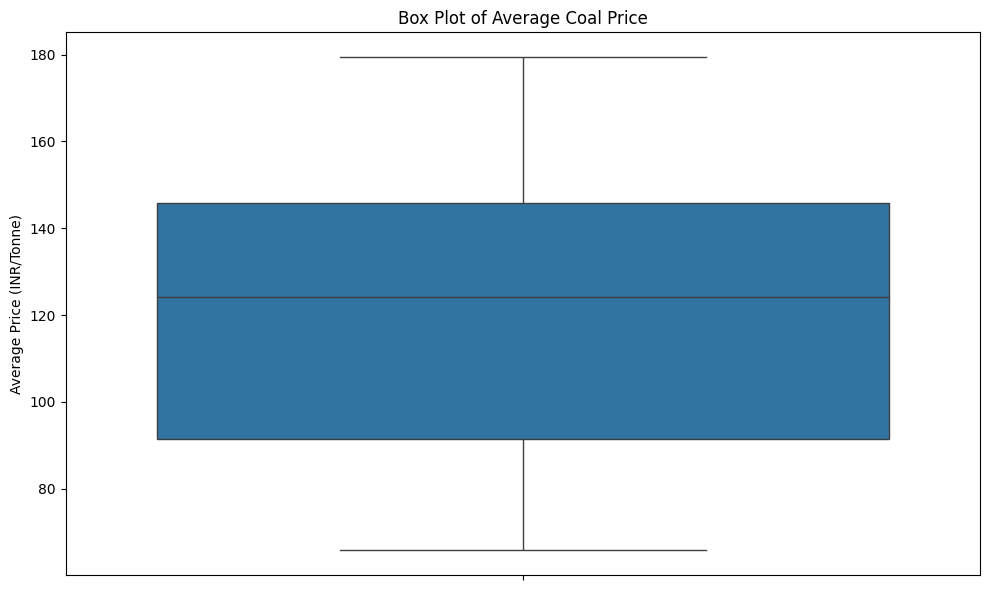

In [28]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    y=df["Average Price (INR/Tonne)"]
)

plt.title("Box Plot of Average Coal Price")
plt.ylabel("Average Price (INR/Tonne)")

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "18_average_price_boxplot.png"), dpi=300)
plt.show()

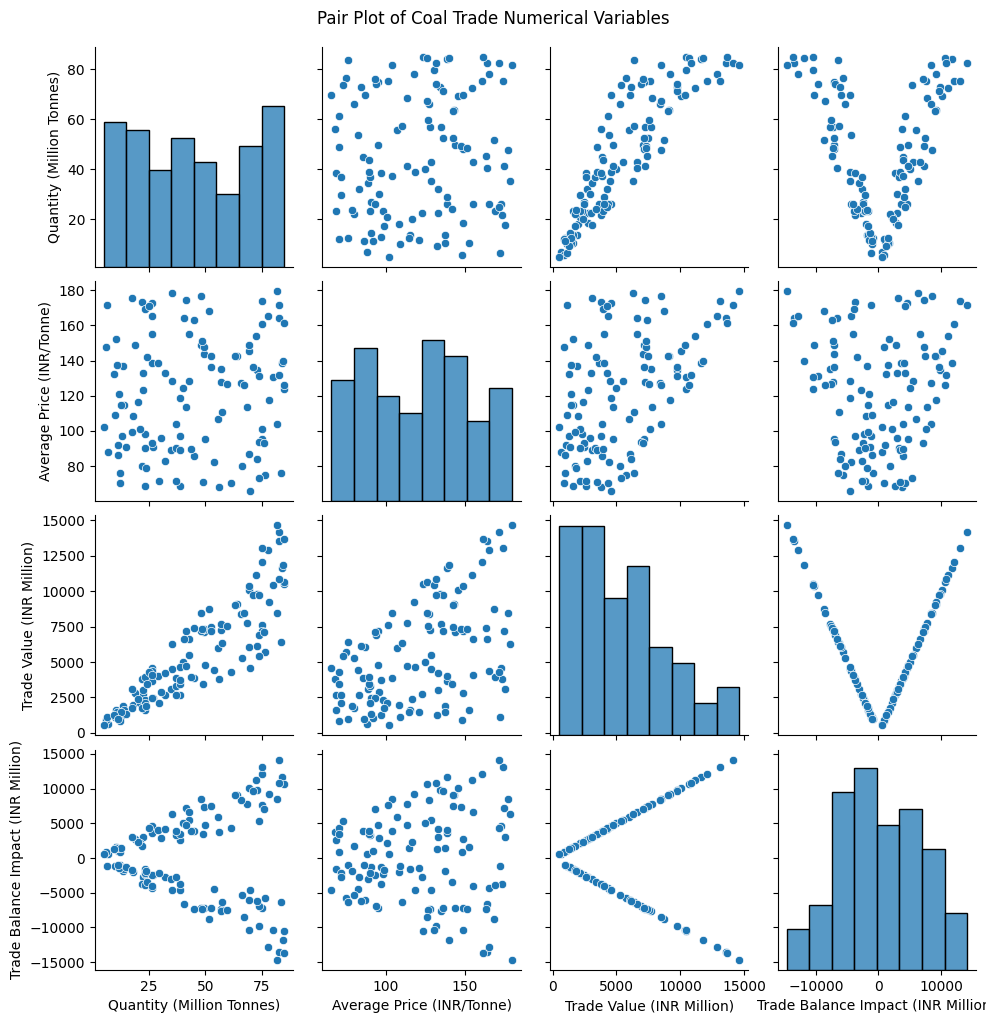

In [29]:
pair_columns = [
    "Quantity (Million Tonnes)",
    "Average Price (INR/Tonne)",
    "Trade Value (INR Million)",
    "Trade Balance Impact (INR Million)"
]

pair_data = df[pair_columns].dropna()

sns.pairplot(
    pair_data,
    diag_kind="hist"
)

plt.suptitle(
    "Pair Plot of Coal Trade Numerical Variables",
    y=1.02
)

plt.savefig(
    os.path.join(output_folder, "19_pair_plot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

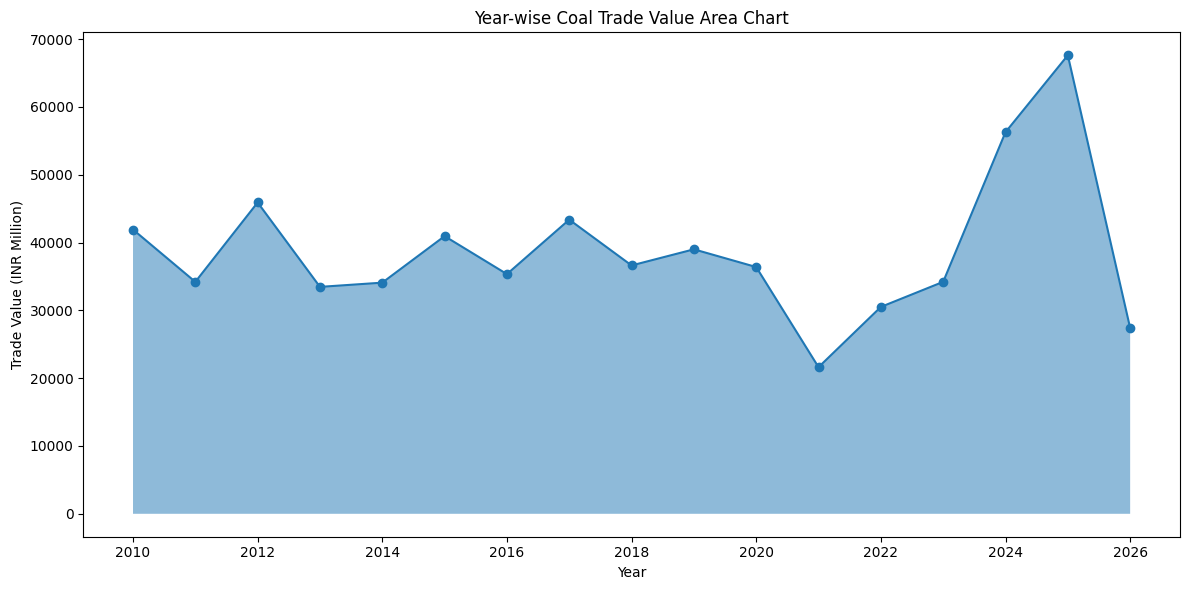

In [30]:
area_data = df.groupby("Year")[
    "Trade Value (INR Million)"
].sum()

plt.figure(figsize=(12, 6))

plt.fill_between(
    area_data.index,
    area_data.values,
    alpha=0.5
)

plt.plot(
    area_data.index,
    area_data.values,
    marker="o"
)

plt.title("Year-wise Coal Trade Value Area Chart")
plt.xlabel("Year")
plt.ylabel("Trade Value (INR Million)")

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "20_trade_value_area_chart.png"), dpi=300)
plt.show()

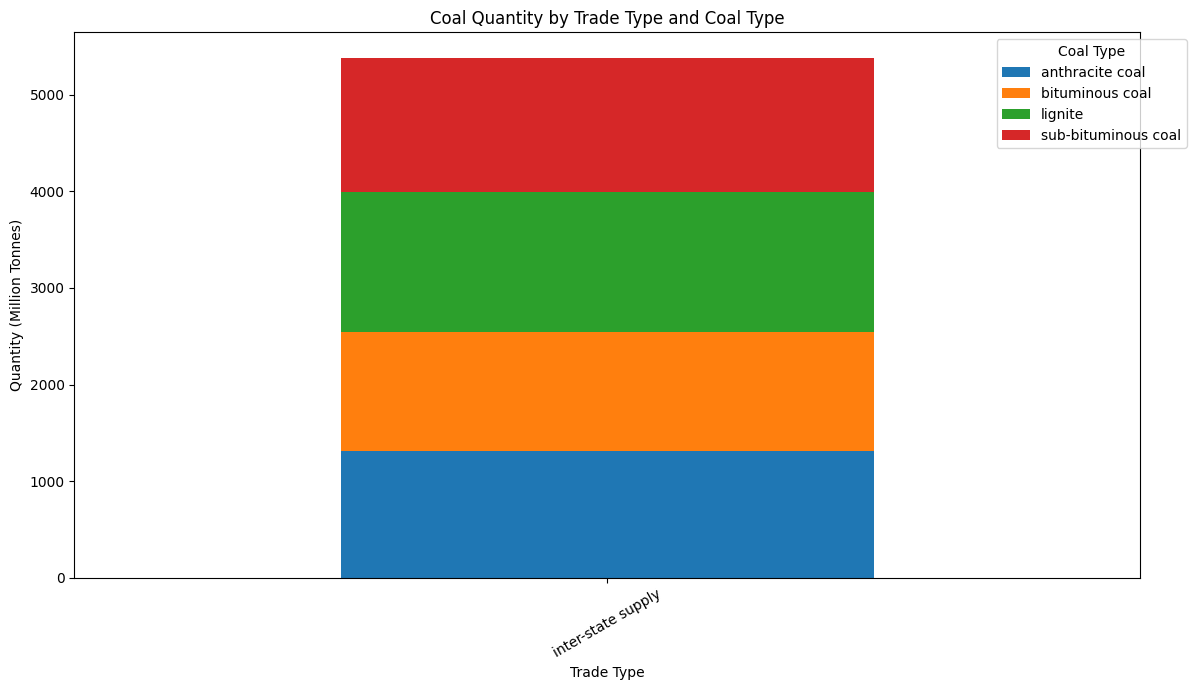

In [31]:
stacked_data = pd.pivot_table(
    df,
    index="Trade Type",
    columns="Coal Type",
    values="Quantity (Million Tonnes)",
    aggfunc="sum",
    fill_value=0
)

stacked_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Coal Quantity by Trade Type and Coal Type")
plt.xlabel("Trade Type")
plt.ylabel("Quantity (Million Tonnes)")
plt.xticks(rotation=30)
plt.legend(title="Coal Type", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "21_stacked_bar_chart.png"), dpi=300)
plt.show()

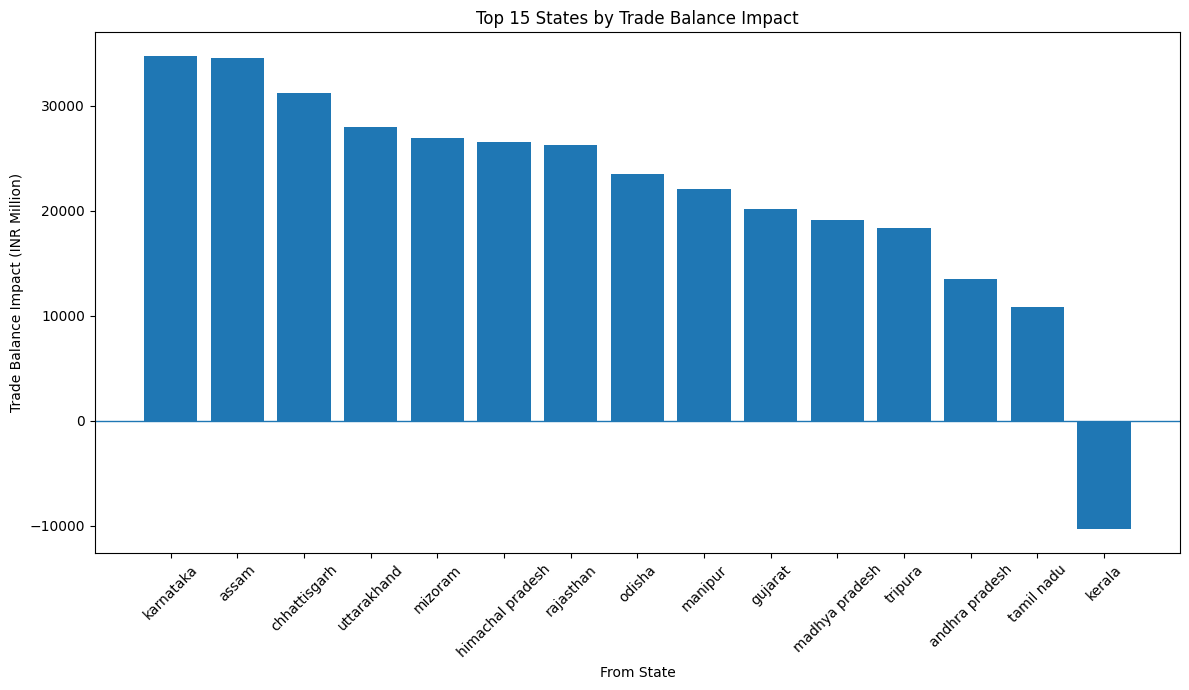

In [33]:
state_balance = df.groupby("From State")[
    "Trade Balance Impact (INR Million)"
].sum().sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 7))

plt.bar(
    state_balance.index.astype(str),
    state_balance.values
)

plt.title("Top 15 States by Trade Balance Impact")
plt.xlabel("From State")
plt.ylabel("Trade Balance Impact (INR Million)")
plt.axhline(y=0, linewidth=1)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "23_state_trade_balance.png"), dpi=300)
plt.show()

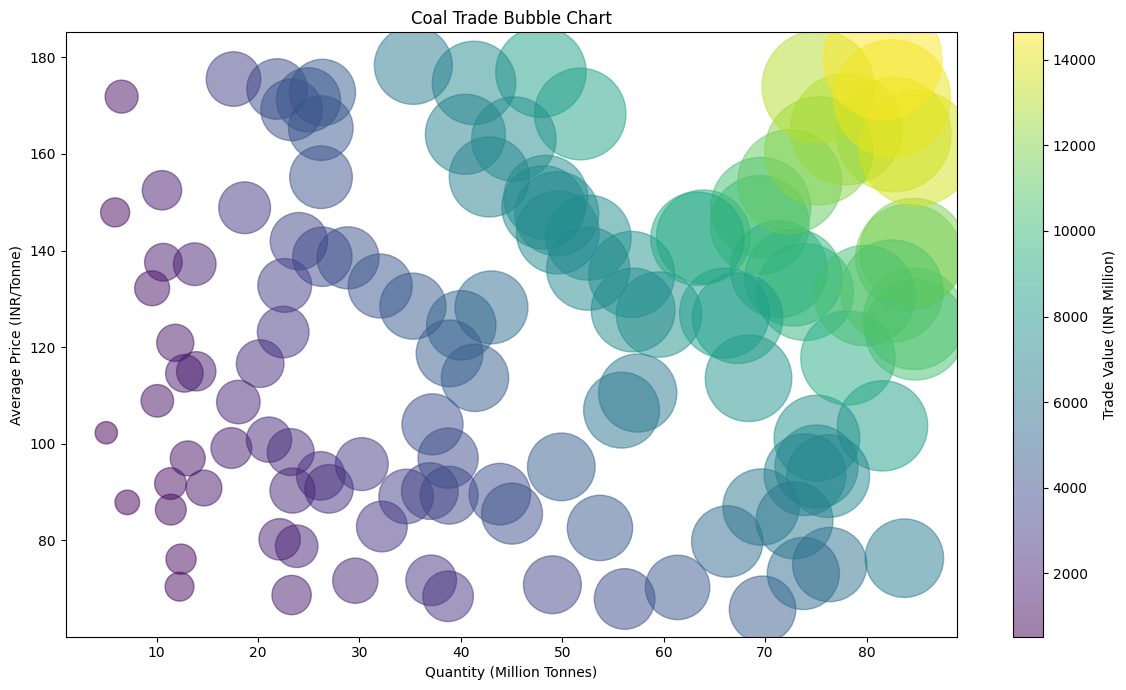

In [34]:
bubble_data = df.dropna(
    subset=[
        "Quantity (Million Tonnes)",
        "Average Price (INR/Tonne)",
        "Trade Value (INR Million)"
    ]
)

plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    bubble_data["Quantity (Million Tonnes)"],
    bubble_data["Average Price (INR/Tonne)"],
    s=np.maximum(
        bubble_data["Trade Value (INR Million)"].abs(),
        1
    ) * 0.5,
    alpha=0.5,
    c=bubble_data["Trade Value (INR Million)"],
    cmap="viridis"
)

plt.colorbar(scatter, label="Trade Value (INR Million)")

plt.title("Coal Trade Bubble Chart")
plt.xlabel("Quantity (Million Tonnes)")
plt.ylabel("Average Price (INR/Tonne)")

plt.tight_layout()
plt.savefig(os.path.join(output_folder, "24_bubble_chart.png"), dpi=300)
plt.show()

In [35]:
import glob
import os
import pandas as pd

image_files = sorted(
    glob.glob(os.path.join(output_folder, "*.png"))
)

print("=" * 55)
print("     COAL TRADE DATA VISUALIZATION REPORT")
print("=" * 55)

print("Total Visualizations Created:", len(image_files))

for i, image in enumerate(image_files, start=1):
    print(f"{i}. {os.path.basename(image)}")

print("\nVisualization folder:")
print(output_folder)

print("\nVisualization Status:")

if len(image_files) >= 25:
    print("SUCCESS: All 25 visualizations are available!")
else:
    print("Some visualizations are missing.")
    print("Check the cells that produced errors.")

print("=" * 55)

     COAL TRADE DATA VISUALIZATION REPORT
Total Visualizations Created: 23
1. 01_yearly_trade_value.png
2. 02_coal_type_distribution.png
3. 03_trade_type_distribution.png
4. 04_state_wise_quantity.png
5. 05_average_price_by_coal_type.png
6. 06_trade_balance_impact.png
7. 08_trade_value_by_coal_type.png
8. 09_correlation_heatmap.png
9. 10_quantity_vs_trade_value.png
10. 11_year_wise_coal_quantity.png
11. 12_state_to_state_trade.png
12. 13_top_trading_states.png
13. 14_coal_vs_trade_type.png
14. 15_average_price_trend.png
15. 16_trade_value_distribution.png
16. 17_quantity_boxplot.png
17. 18_average_price_boxplot.png
18. 19_pair_plot.png
19. 20_trade_value_area_chart.png
20. 21_stacked_bar_chart.png
21. 22_violin_plot.png
22. 23_state_trade_balance.png
23. 24_bubble_chart.png

Visualization folder:
C:/Users/Manisha Gajula/OneDrive/Desktop\Coal_Trade_Visualizations

Visualization Status:
Some visualizations are missing.
Check the cells that produced errors.
